# Indian Roads Dataset Visualization
First, let's import the necessary libraries and load the dataset to inspect its structure and columns.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load dataset
df = pd.read_csv('/content/indian_roads_dataset.csv')

# Display schema and preview
print("Columns present in dataset:", df.columns.tolist())
display(df.head(5))

Columns present in dataset: ['accident_id', 'city', 'state', 'latitude', 'longitude', 'date', 'time', 'hour', 'day_of_week', 'is_weekend', 'road_type', 'lanes', 'traffic_signal', 'weather', 'visibility', 'temperature', 'traffic_density', 'cause', 'accident_severity', 'vehicles_involved', 'casualties', 'is_peak_hour', 'festival', 'risk_score']


,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,visibility,temperature,traffic_density,cause,accident_severity,vehicles_involved,casualties,is_peak_hour,festival,risk_score
0,0,Pune,Maharashtra,18.680827,73.930388,2023-10-22,5:00,5,Sunday,1,...,low,32,high,weather,fatal,2,2,0,NaN,0.85
1,1,Mumbai,Maharashtra,18.817732,72.790846,2023-05-21,4:00,4,Sunday,1,...,high,34,low,weather,major,4,3,0,NaN,0.10
2,2,Mumbai,Maharashtra,19.096889,72.819424,2024-07-10,13:00,13,Wednesday,0,...,low,21,medium,weather,minor,1,1,0,NaN,0.45
3,3,Chandigarh,Punjab,30.787805,76.847507,2025-03-30,11:00,11,Sunday,1,...,low,30,high,distraction,minor,5,2,0,NaN,0.65
4,4,Chennai,Tamil Nadu,12.965155,80.283313,2024-01-25,16:00,16,Thursday,0,...,high,24,low,distraction,minor,2,1,0,NaN,0.10


## 1. Line Chart
We will plot a line chart to show a continuous trend. (If there is no date/time column, we will plot index-based trends or trends over sorted values).

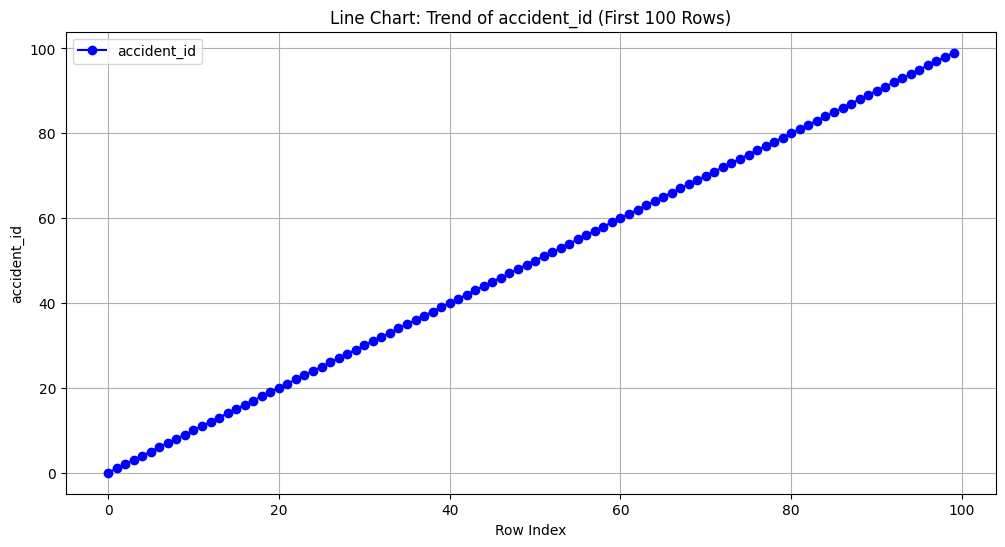

In [10]:
# Identify numerical columns for line plot
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

plt.figure(figsize=(12, 6))
if len(num_cols) >= 1:
    # Plotting first numerical column as a line trend
    plt.plot(df.index[:100], df[num_cols[0]].iloc[:100], marker='o', color='b', label=num_cols[0])
    plt.title(f'Line Chart: Trend of {num_cols[0]} (First 100 Rows)')
    plt.xlabel('Row Index')
    plt.ylabel(num_cols[0])
    plt.legend()
    plt.grid(True)
else:
    print("No numerical columns available for line chart.")
plt.show()

## 2. Scatter Plot
We will plot a scatter plot to observe relationships between two numerical features.

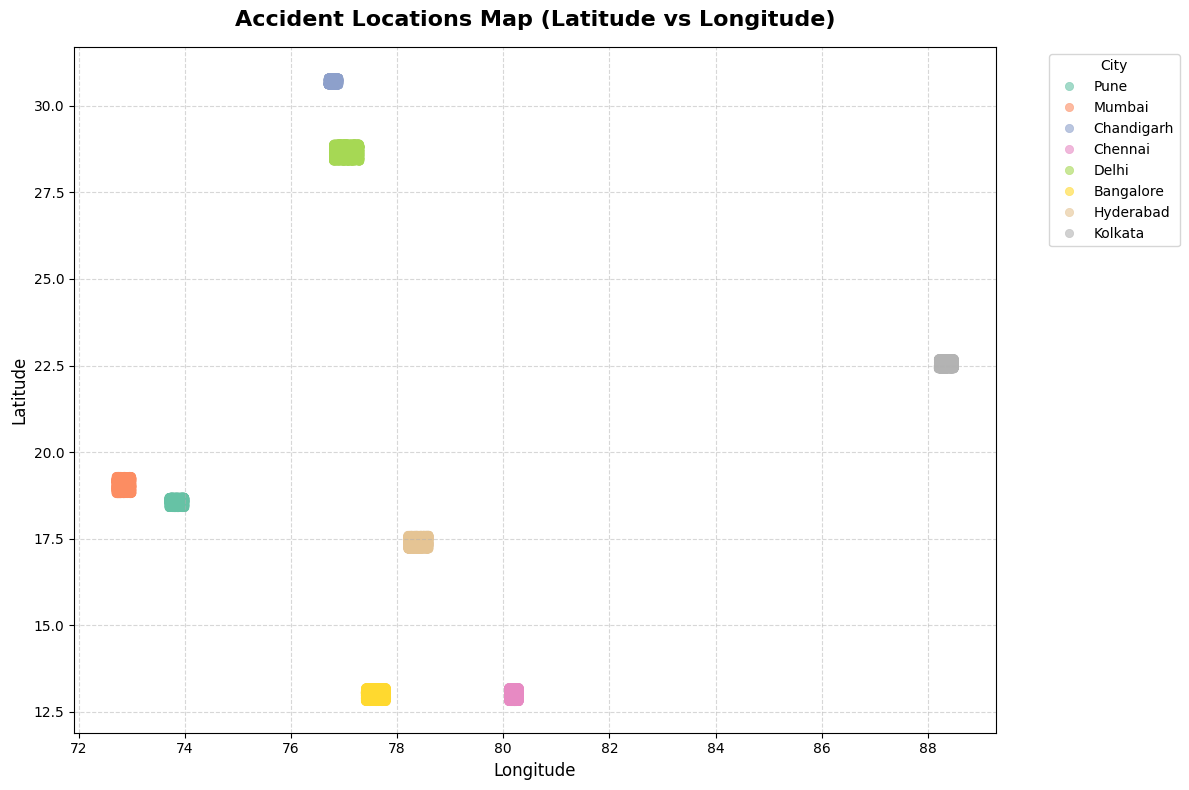

In [11]:
plt.figure(figsize=(12, 8))
# Plotting Longitude vs Latitude to represent geographical accident clusters clearly per City
sns.scatterplot(
    data=df,
    x='longitude',
    y='latitude',
    hue='city',
    palette='Set2',
    alpha=0.6,
    edgecolor=None
)
plt.title('Accident Locations Map (Latitude vs Longitude)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.legend(title='City', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 3. Bar Graph
Let us visualize categorical value counts or aggregations using a bar chart.

/tmp/ipykernel_2464/3065451848.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.values, y=top_categories.index, palette='viridis')


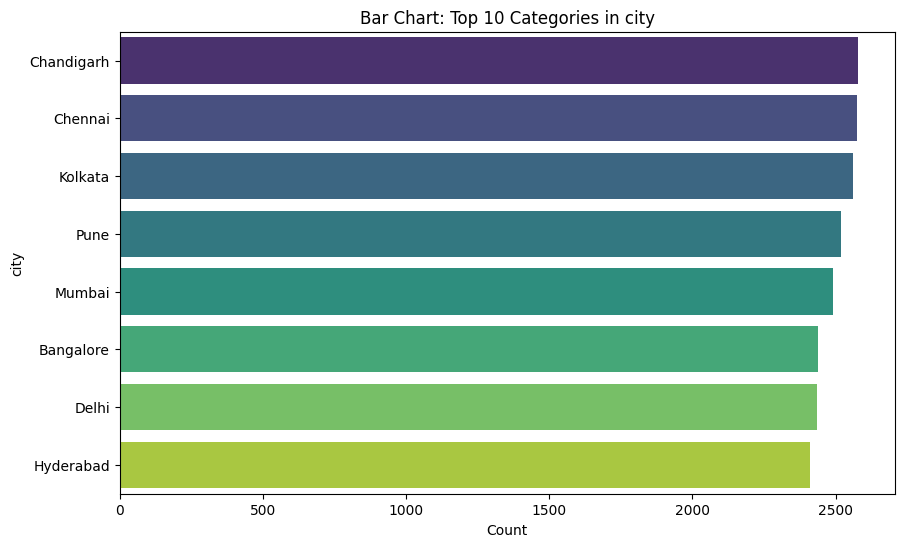

In [12]:
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

plt.figure(figsize=(10, 6))
if len(cat_cols) >= 1:
    # Get top 10 categories to avoid overcrowding the plot
    top_categories = df[cat_cols[0]].value_counts().head(10)
    sns.barplot(x=top_categories.values, y=top_categories.index, palette='viridis')
    plt.title(f'Bar Chart: Top 10 Categories in {cat_cols[0]}')
    plt.xlabel('Count')
    plt.ylabel(cat_cols[0])
else:
    # Fallback to numerical index if no categorical column exists
    sns.barplot(x=df.index[:10], y=df[num_cols[0]].iloc[:10] if len(num_cols) > 0 else [])
    plt.title('Bar Chart of First 10 Values')
plt.show()

## 4. Pie Chart
We will generate a pie chart representing the proportion of the top categorical distributions.

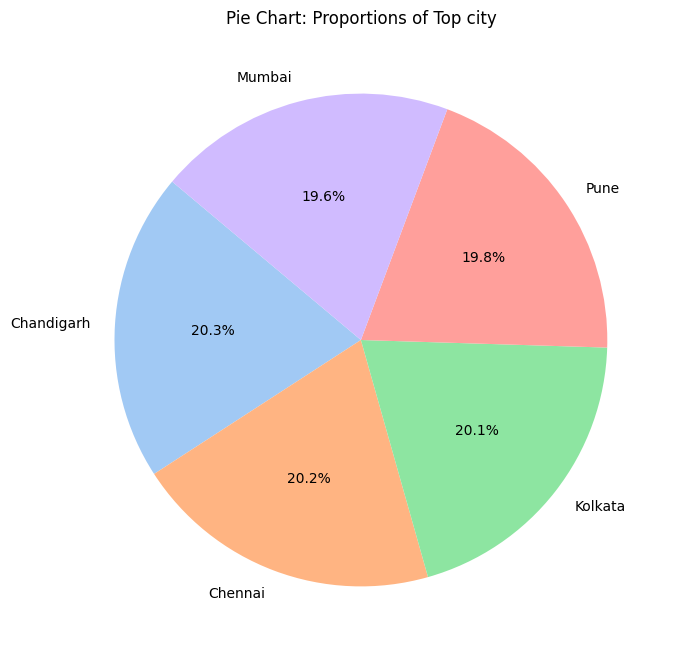

In [13]:
if len(cat_cols) >= 1:
    plt.figure(figsize=(8, 8))
    category_counts = df[cat_cols[0]].value_counts().head(5)
    plt.pie(category_counts, labels=category_counts.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
    plt.title(f'Pie Chart: Proportions of Top {cat_cols[0]}')
else:
    print("No categorical variables found for pie chart.")
plt.show()

## 5. Histogram
Let's plot a histogram with a Kernel Density Estimate (KDE) line to inspect the frequency distribution of numerical parameters.

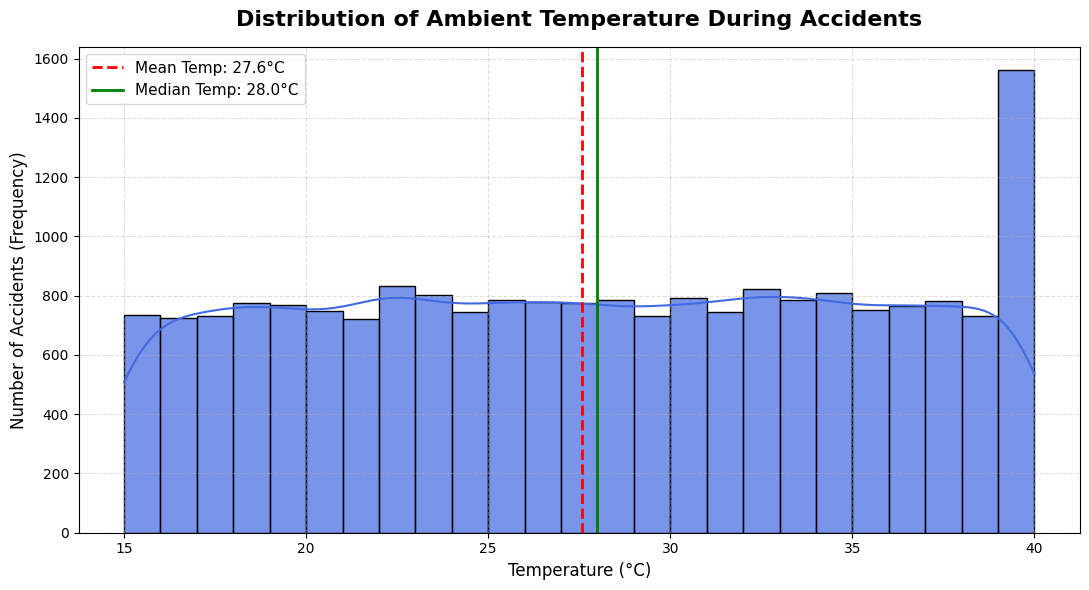

In [14]:
plt.figure(figsize=(11, 6))
# Histogram of Temperature during accidents with mean/median markings for instant understanding
sns.histplot(df['temperature'], kde=True, color='royalblue', bins=25, edgecolor='black', alpha=0.7)

# Adding statistics lines for better readability
mean_temp = df['temperature'].mean()
median_temp = df['temperature'].median()
plt.axvline(mean_temp, color='red', linestyle='--', linewidth=2, label=f'Mean Temp: {mean_temp:.1f}°C')
plt.axvline(median_temp, color='green', linestyle='-', linewidth=2, label=f'Median Temp: {median_temp:.1f}°C')

plt.title('Distribution of Ambient Temperature During Accidents', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Temperature (°C)', fontsize=12)
plt.ylabel('Number of Accidents (Frequency)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

## 6. Heatmap
This cell plots a correlation heatmap to display coefficients between numerical columns of the dataset.

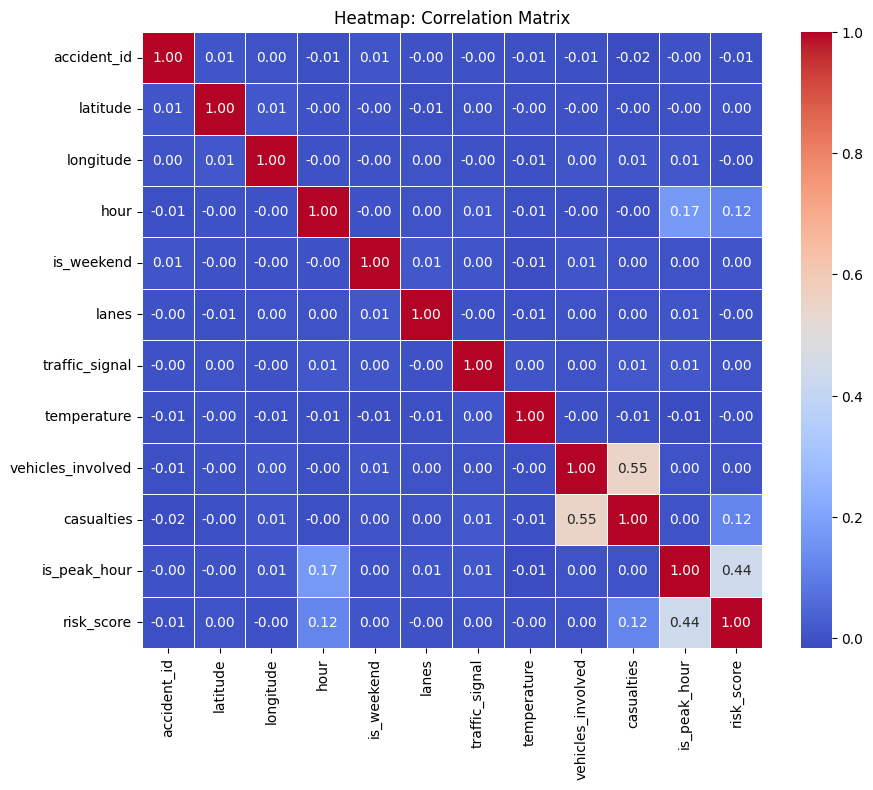

In [15]:
if len(num_cols) >= 2:
    plt.figure(figsize=(10, 8))
    correlation_matrix = df[num_cols].corr()
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
    plt.title('Heatmap: Correlation Matrix')
else:
    print("Need at least 2 numerical columns to plot a correlation heatmap.")
plt.show()